# Plateau-scheduled curricula — five-seed analysis

Does the staged order improve binding, or does `ReduceLROnPlateau` change the optimization path? This notebook reads the **3,000-update, five-seed plateau experiment**; no training occurs here. Every figure and summary table is saved in the experiment's own directory.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path().cwd().parent.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

source = PROJECT_ROOT / 'outputs/medium_world/experiments/plateau_five_seeds/schedule_comparison.json'
report = json.loads(source.read_text(encoding='utf-8'))
runs = report['runs']
SCHEDULES = ('mixed', 'staged', 'reverse')
TASKS = ('color', 'shape', 'conjunction', 'pair')
OUTPUT_DIR = source.parent

def save_figure(fig, filename):
    fig.savefig(OUTPUT_DIR / f'{filename}.png', dpi=300,
                bbox_inches='tight', facecolor='white')

## 1. What did this experiment control?

The schedules receive the same **150,000 question presentations** and 3,000 optimizer updates (12 main and 3 common repetitions per example). They differ in task order and in *realized learning rate*, because the scheduler responds separately to each run's overall ID-development loss.

In [2]:
protocol = pd.DataFrame([{
    'seed': r['seed'], 'schedule': r['schedule'], 'updates': r['steps_run'],
    'total_presentations': r['exposure_plan']['total_presentations'],
    'per_example': r['exposure_plan']['repetitions_per_example'],
    **r['exposure_plan']['counts_by_template']
} for r in runs])
display(protocol.groupby('schedule')[['updates', 'total_presentations', 'per_example']]
        .agg(['min', 'max']).reindex(SCHEDULES))
protocol.to_csv(OUTPUT_DIR / 'exposure_by_seed.csv', index=False)

updates       total_presentations         per_example    
             min   max                 min     max         min max
schedule                                                          
mixed       3000  3000              150000  150000          15  15
staged      3000  3000              150000  150000          15  15
reverse     3000  3000              150000  150000          15  15

## 2. Which order learned binding best?

Compare **fixed-final** performance, not a retrospectively selected best checkpoint. Report binding on familiar ID-development examples, binding on withheld-combination OOD-development examples, and the full-trajectory binding AULC. The AULC is a training-efficiency metric in global updates, not in binding examples.

overall_id         pair        shape       conjunction        \
               mean   std   mean   std   mean   std        mean   std   
schedule                                                                
mixed         72.46  2.39  53.59  2.73  61.33  1.32       78.12  3.75   
staged        71.68  2.35  54.14  3.78  60.47  1.45       76.95  4.48   
reverse       63.63  6.33  52.81  1.69  56.25  5.12       66.25  7.70   

         ood_pair       ood_bce       pair_aulc        
             mean   std    mean   std      mean   std  
schedule                                               
mixed        54.2  1.98    0.71  0.04     52.99  1.01  
staged       52.3  5.52    0.72  0.04     52.08  0.92  
reverse      51.7  2.29    0.72  0.03     51.36  1.45

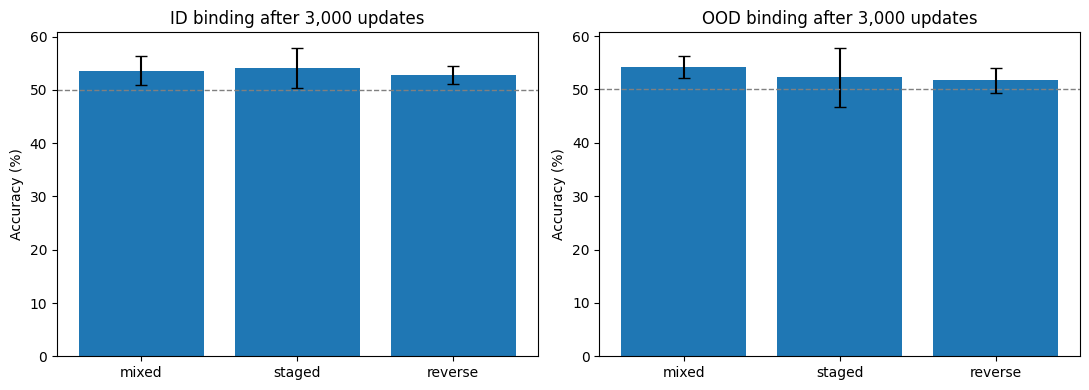

In [3]:
rows = []
for r in runs:
    f = r['final']
    rows.append({
        'seed': r['seed'], 'schedule': r['schedule'],
        'overall_id': 100 * f['id_dev']['accuracy'],
        'ood_pair': 100 * f['ood_dev']['by_template']['pair'],
        'ood_bce': f['ood_dev']['loss'],
        'pair_aulc': 100 * r['id_pair_aulc'],
        'final_lr': r['final']['lr'],
        'lr_reductions': len(r['lr_reductions']),
        **{task: 100 * f['id_dev']['by_template'][task] for task in TASKS}
    })
final = pd.DataFrame(rows)
metrics = ['overall_id', 'pair', 'shape', 'conjunction', 'ood_pair', 'ood_bce', 'pair_aulc']
display(final.groupby('schedule')[metrics].agg(['mean', 'std']).reindex(SCHEDULES).round(2))
final.to_csv(OUTPUT_DIR / 'final_by_seed.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric, title in zip(axes, ('pair', 'ood_pair'), ('ID binding', 'OOD binding')):
    values = final.groupby('schedule')[metric].agg(['mean', 'std']).reindex(SCHEDULES)
    ax.bar(SCHEDULES, values['mean'], yerr=values['std'], capsize=4)
    ax.axhline(50, color='gray', linestyle='--', linewidth=1)
    ax.set(title=title + ' after 3,000 updates', ylabel='Accuracy (%)')
plt.tight_layout()
save_figure(fig, 'final_binding_id_ood')
plt.show()

## 3. Paired differences across seeds

Seed pairing compares two schedules that start from the same random initialization. For metric $A$, the paired effect is $\Delta_s=A_{s,1}-A_{s,2}$. A percentile interval is computed by resampling the **five seed-level differences**, not individual questions. These intervals are descriptive with such a small seed count.

,contrast,metric,mean_pp,ci_low,ci_high,wins
0,staged − mixed,pair,0.55,-1.72,2.58,3
1,staged − mixed,pair_aulc,-0.91,-1.56,-0.09,1
2,staged − mixed,ood_pair,-1.90,-6.25,3.90,1
3,staged − mixed,overall_id,-0.78,-2.36,0.57,2
4,staged − mixed,shape,-0.86,-1.80,0.08,1
5,reverse − mixed,pair,-0.78,-3.52,1.64,2
6,reverse − mixed,pair_aulc,-1.63,-3.02,-0.55,0
7,reverse − mixed,ood_pair,-2.50,-5.00,-0.20,1
8,reverse − mixed,overall_id,-8.83,-14.18,-3.63,0
9,reverse − mixed,shape,-5.08,-8.67,-1.80,0


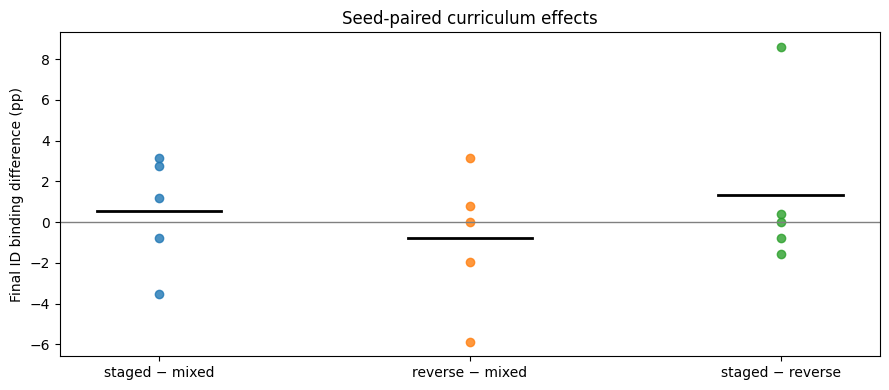

In [4]:
rng = np.random.default_rng(42)
comparisons = (('staged', 'mixed'), ('reverse', 'mixed'), ('staged', 'reverse'))
paired = []
for first, second in comparisons:
    for metric in ('pair', 'pair_aulc', 'ood_pair', 'overall_id', 'shape'):
        p = final.pivot(index='seed', columns='schedule', values=metric)
        delta = (p[first] - p[second]).to_numpy()
        boot = rng.choice(delta, size=(10000, len(delta)), replace=True).mean(axis=1)
        low, high = np.percentile(boot, [2.5, 97.5])
        paired.append({'contrast': first + ' − ' + second, 'metric': metric,
                       'mean_pp': delta.mean(), 'ci_low': low, 'ci_high': high,
                       'wins': int((delta > 0).sum())})
paired = pd.DataFrame(paired)
display(paired.round(2))
paired.to_csv(OUTPUT_DIR / 'paired_differences.csv', index=False)

fig, ax = plt.subplots(figsize=(9, 4))
for i, (first, second) in enumerate(comparisons):
    p = final.pivot(index='seed', columns='schedule', values='pair')
    delta = p[first] - p[second]
    ax.scatter([i] * len(delta), delta, alpha=.8)
    ax.plot([i-.2, i+.2], [delta.mean()]*2, color='black', linewidth=2)
ax.axhline(0, color='gray', linewidth=1)
ax.set(xticks=range(len(comparisons)), xticklabels=[f'{a} − {b}' for a,b in comparisons],
       ylabel='Final ID binding difference (pp)', title='Seed-paired curriculum effects')
plt.tight_layout()
save_figure(fig, 'paired_binding_differences')
plt.show()

## 4. Learning curves: final skill versus early efficiency

Binding AULC is approximately $T^{-1}\int_0^T A_{\mathrm{pair}}(t)\,dt$, with $T=3,000$. By measuring from step zero, staged training is penalized for its initial time without binding supervision—intentionally, because this measures *overall learning time*. It does **not** tell us whether the binding-only updates are individually more efficient.

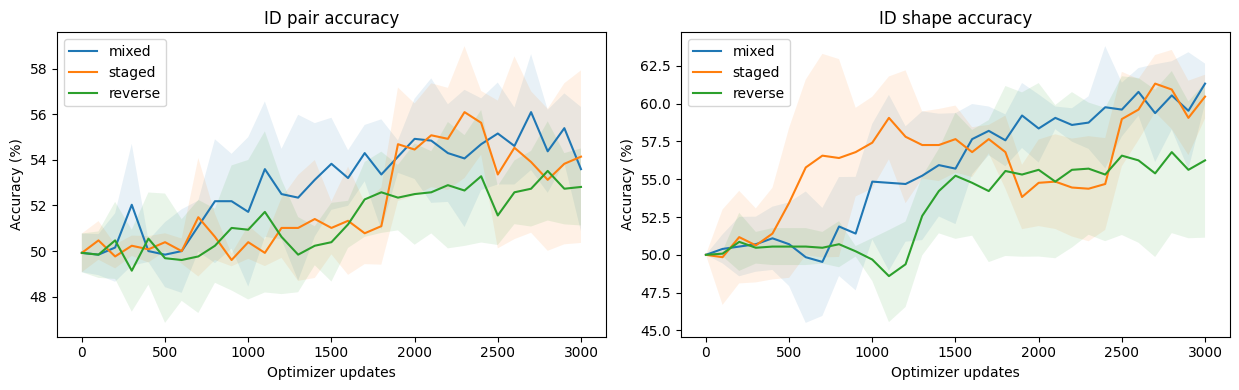

In [5]:
history = pd.DataFrame([{
    'seed': r['seed'], 'schedule': r['schedule'], 'step': h['step'],
    'phase': h['phase'], 'lr': h['lr_after'],
    'id_loss': h['id_dev']['loss'],
    **{task: 100 * h['id_dev']['by_template'][task] for task in TASKS}
} for r in runs for h in r['history']])
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4))
for ax, task in zip(axes, ('pair', 'shape')):
    for schedule in SCHEDULES:
        v = history[history.schedule == schedule].groupby('step')[task].agg(['mean', 'std'])
        ax.plot(v.index, v['mean'], label=schedule)
        ax.fill_between(v.index, v['mean'] - v['std'], v['mean'] + v['std'], alpha=.1)
    ax.set(title='ID ' + task + ' accuracy', xlabel='Optimizer updates', ylabel='Accuracy (%)')
    ax.legend()
plt.tight_layout()
save_figure(fig, 'binding_and_shape_learning_curves')
plt.show()

## 5. Why did `ReduceLROnPlateau` interact with curriculum order?

AdamW updates parameters using adaptive gradient moments, with a global step size $\eta$. Here `ReduceLROnPlateau` monitors **overall ID-dev BCE**, and after sustained lack of improvement multiplies the LR by 0.5 (down to $10^{-6}$).

$$\eta_{\mathrm{new}}=\max(10^{-6},\;0.5\eta_{\mathrm{old}}).$$

Unlike a frozen learning-rate schedule, this policy reacts to *which tasks are currently being trained*. Since the metric includes tasks the staged model has not yet seen, LR reductions can occur for a curriculum-specific reason. Stage transitions do not reset the optimizer or scheduler.

lr_reductions          final_lr                   
                  mean min max      mean       min      max
schedule                                                   
mixed              0.0   0   0  0.000100  0.000100  0.00010
staged             1.8   1   3  0.000032  0.000013  0.00005
reverse            2.2   0   5  0.000038  0.000003  0.00010

,seed,schedule,step,lr_before,lr_after
4,43,reverse,500,0.000100,0.000050
5,43,reverse,1800,0.000050,0.000025
6,43,reverse,2200,0.000025,0.000013
10,44,reverse,500,0.000100,0.000050
11,44,reverse,1100,0.000050,0.000025
12,44,reverse,1500,0.000025,0.000013
13,44,reverse,2300,0.000013,0.000006
14,44,reverse,2700,0.000006,0.000003
16,45,reverse,600,0.000100,0.000050
17,45,reverse,1200,0.000050,0.000025


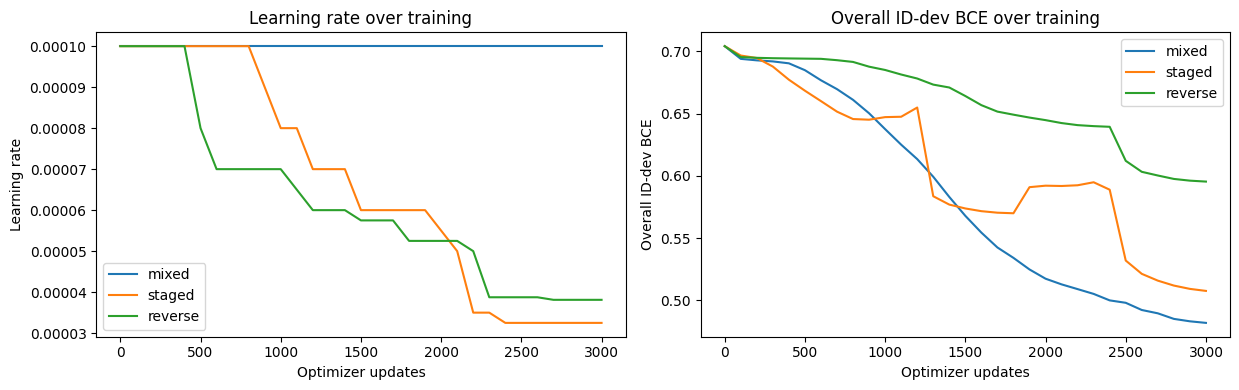

In [6]:
lr_events = pd.DataFrame([{
    'seed': r['seed'], 'schedule': r['schedule'],
    'step': event['step'], 'lr_before': event['from'], 'lr_after': event['to']
} for r in runs for event in r['lr_reductions']])
display(final.groupby('schedule')[['lr_reductions', 'final_lr']].agg(['mean', 'min', 'max']).reindex(SCHEDULES))
display(lr_events.sort_values(['schedule', 'seed', 'step']))
lr_events.to_csv(OUTPUT_DIR / 'learning_rate_reductions.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4))
for ax, metric, ylabel in zip(axes, ('lr', 'id_loss'), ('Learning rate', 'Overall ID-dev BCE')):
    for schedule in SCHEDULES:
        v = history[history.schedule == schedule].groupby('step')[metric].mean()
        ax.plot(v.index, v.values, label=schedule)
    ax.set(title=ylabel + ' over training', xlabel='Optimizer updates', ylabel=ylabel)
    ax.legend()
plt.tight_layout()
save_figure(fig, 'adaptive_lr_and_validation_loss')
plt.show()

## 6. Does learning a new task interfere with an earlier one?

For each phase boundary, compare the **last recorded evaluation before** versus the **first evaluation after** the stage change. A negative delta is consistent with interference, but it includes another evaluation interval of training and is not a causal estimate of catastrophic forgetting.

color  shape  conjunction  pair
schedule transition                                                
mixed    initial → mixed             0.94   0.39        -0.23 -0.08
         mixed → common_mixed        0.23  -0.16         1.02  0.47
reverse  attributes → common_mixed   0.31   1.25         1.48 -1.72
         binding → conjunction       3.12  -0.08         2.97  0.16
         conjunction → attributes    5.16   3.20         0.70 -0.78
         initial → binding          -0.94   0.08        -0.16 -0.08
staged   attributes → conjunction   -3.67  -0.55         7.42  0.00
         binding → common_mixed     15.70   4.30        12.34 -2.27
         conjunction → binding     -14.84  -2.97       -12.97  3.59
         initial → attributes        0.31  -0.16         0.78  0.55

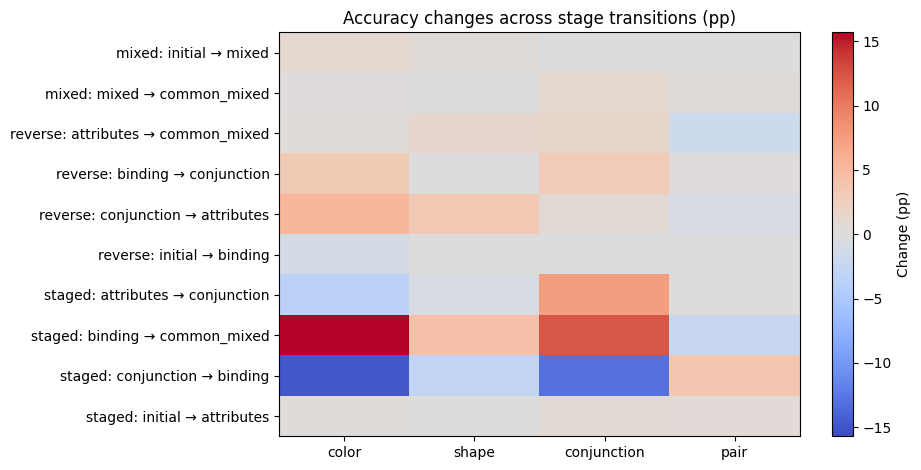

In [7]:
changes = []
for r in runs:
    for before, after in zip(r['history'], r['history'][1:]):
        if before['phase'] == after['phase']:
            continue
        changes.append({
            'seed': r['seed'], 'schedule': r['schedule'],
            'transition': before['phase'] + ' → ' + after['phase'],
            'step_before': before['step'], 'step_after': after['step'],
            **{task: 100 * (after['id_dev']['by_template'][task] -
                            before['id_dev']['by_template'][task]) for task in TASKS}
        })
changes = pd.DataFrame(changes)
changes.to_csv(OUTPUT_DIR / 'transition_changes.csv', index=False)
summary = changes.groupby(['schedule', 'transition'])[list(TASKS)].mean()
display(summary.round(2))

fig, ax = plt.subplots(figsize=(9.5, 4.8))
values = summary.to_numpy()
scale = np.abs(values).max()
im = ax.imshow(values, cmap='coolwarm', vmin=-scale, vmax=scale, aspect='auto')
ax.set(xticks=range(len(TASKS)), xticklabels=TASKS,
       yticks=range(len(summary)),
       yticklabels=[f'{s}: {t}' for s,t in summary.index],
       title='Accuracy changes across stage transitions (pp)')
fig.colorbar(im, ax=ax, label='Change (pp)')
plt.tight_layout()
save_figure(fig, 'transition_interference')
plt.show()

## 7. Learning *within* each curriculum stage

The immediate transition delta misses slow transfer and sustained decline. For stage \(s\), measure \(G_{s,k}=A_k(t_s^{\mathrm{end}})-A_k(t_s^{\mathrm{start}})\) on **every task**. The last available evaluation at or before each boundary is used (some stages end between logged evaluations). End-of-stage matrices show what was known after attributes, conjunction, binding and mixed consolidation. The phases differ by schedule, so compare both stage and global step.

accuracy_end  change_pp
schedule phase        task                                
mixed    common_mixed color               96.80       1.72
                      conjunction         78.12       1.80
                      pair                53.59      -1.09
                      shape               61.33       1.56
         mixed        color               95.08      43.52
                      conjunction         76.33      26.17
                      pair                54.69       4.77
                      shape               59.77       9.77
reverse  attributes   color               77.50      17.73
                      conjunction         64.61       6.33
                      pair                53.28       2.66
                      shape               55.31       5.94
         binding      color               51.02      -0.55
                      conjunction         50.70       0.55
                      pair                49.61      -0.31
                      shape               50.55       0.55
         common_mixed color               79.22       1.72
                      conjunction         66.25       1.64
                      pair                52.81      -0.47
                      shape               56.25       0.94
         conjunction  color               59.77       8.75
                      conjunction         58.28       7.58
                      pair                50.62       1.02
                      shape               49.38      -1.17
staged   attributes   color               91.48      39.92
                      conjunction         67.50      17.34
                      pair                51.02       1.09
                      shape               57.81       7.81
         binding      color               77.73     -15.55
                      conjunction         63.59     -13.44
                      pair                55.62       4.53
                      shape               54.69      -2.11
         common_mixed color               95.16      17.42
                      conjunction         76.95      13.36
                      pair                54.14      -1.48
                      shape               60.47       5.78
         conjunction  color               93.28       1.80
                      conjunction         77.03       9.53
                      pair                51.09       0.08
                      shape               56.80      -1.02

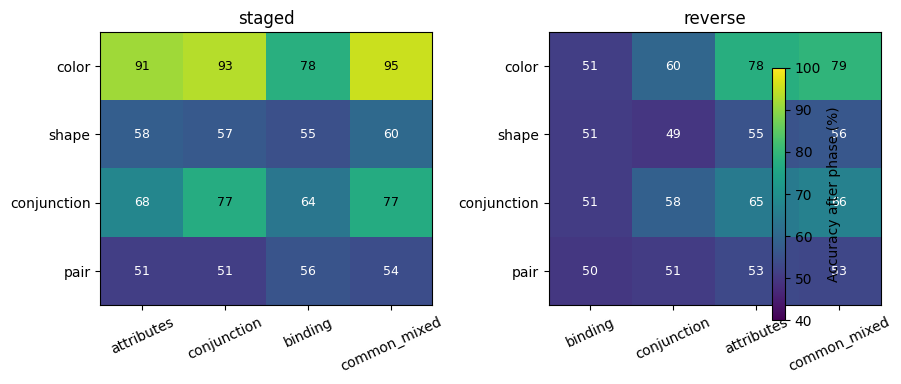

In [8]:
phase_rows = []
for r in runs:
    snapshots = {h['step']: h for h in r['history']}
    start = 0
    for item in r['exposure_plan']['phases']:
        end = start + item['presentations'] // report['config']['batch_size']
        observed_end = max(t for t in snapshots if t <= end)
        observed_start = max(t for t in snapshots if t <= start)
        for task in TASKS:
            before = 100 * snapshots[observed_start]['id_dev']['by_template'][task]
            after = 100 * snapshots[observed_end]['id_dev']['by_template'][task]
            phase_rows.append({'seed': r['seed'], 'schedule': r['schedule'],
                               'phase': item['name'], 'start': start, 'end': end,
                               'observed_start': observed_start,
                               'observed_end': observed_end,
                               'task': task, 'accuracy_start': before,
                               'accuracy_end': after, 'change_pp': after - before})
        start = end
phase_scores = pd.DataFrame(phase_rows)
phase_scores.to_csv(OUTPUT_DIR / 'phase_skill_changes.csv', index=False)
display(phase_scores.groupby(['schedule', 'phase', 'task'])[['accuracy_end', 'change_pp']].mean().round(2))
HEAT_SCHEDULES = ('staged', 'reverse')
fig, axes = plt.subplots(1, len(HEAT_SCHEDULES), figsize=(5.1 * len(HEAT_SCHEDULES), 4.2))
for ax, schedule in zip(np.atleast_1d(axes), HEAT_SCHEDULES):
    frame = phase_scores[phase_scores.schedule == schedule]
    table = frame.groupby(['task', 'phase'])['accuracy_end'].mean().unstack('phase')
    order = list(dict.fromkeys(frame[frame.seed == frame.seed.min()]['phase']))
    table = table.reindex(index=TASKS, columns=order)
    im = ax.imshow(table, vmin=40, vmax=100, cmap='viridis', aspect='auto')
    ax.set(yticks=range(len(TASKS)), yticklabels=TASKS,
           xticks=range(len(order)), xticklabels=order, title=schedule)
    ax.tick_params(axis='x', rotation=25)
    for i in range(len(TASKS)):
        for j in range(len(order)):
            ax.text(j, i, f'{table.iloc[i, j]:.0f}', ha='center', va='center',
                    fontsize=9, color='white' if table.iloc[i, j] < 68 else 'black')
fig.colorbar(im, ax=np.atleast_1d(axes).tolist(), label='Accuracy after phase (%)', shrink=.78)
fig.subplots_adjust(wspace=.35, bottom=.23, right=.89)
save_figure(fig, 'phase_skill_matrices')
plt.show()

## 8. Immediate interference, deepest drop, and recovery

A loss after the first 100 updates is not necessarily permanent forgetting. For a previously trained skill, compare its pre-binding accuracy with the **lowest** accuracy reached during binding, then measure recovery under the final mixed phase. Here, \(F_k=\max(0,A_k(t_0)-\min_{t_0<t\le t_1}A_k(t))\). This is an observed performance drop, not a causal ablation.

In [9]:
FORGET_SCHEDULES = ('staged',)
forget_rows = []
for r in runs:
    if r['schedule'] not in FORGET_SCHEDULES:
        continue
    plan = r['exposure_plan']['phases']
    start = sum(p['presentations'] for p in plan[:next(i for i, p in enumerate(plan)
                 if p['name'] == 'binding')]) // report['config']['batch_size']
    end = start + next(p['presentations'] for p in plan if p['name'] == 'binding') // report['config']['batch_size']
    hist = {h['step']: h for h in r['history']}
    pre_binding = max(t for t in hist if t <= start)
    observed_end = max(t for t in hist if t <= end)
    during = [h for h in r['history'] if start < h['step'] <= end]
    for task in ('color', 'shape', 'conjunction'):
        before = 100 * hist[pre_binding]['id_dev']['by_template'][task]
        values = [100 * h['id_dev']['by_template'][task] for h in during]
        at_end = 100 * hist[observed_end]['id_dev']['by_template'][task]
        at_final = 100 * r['final']['id_dev']['by_template'][task]
        forget_rows.append({'seed': r['seed'], 'schedule': r['schedule'],
                            'task': task, 'binding_start': start, 'binding_end': end,
                            'change_first_100': values[0] - before,
                            'max_drop_pp': max(0, before - min(values)),
                            'change_binding_stage': at_end - before,
                            'recovery_after_binding': at_final - at_end})
forgetting = pd.DataFrame(forget_rows)
forgetting.to_csv(OUTPUT_DIR / 'binding_forgetting_recovery.csv', index=False)
display(forgetting.groupby(['schedule', 'task'])
        [['change_first_100', 'max_drop_pp', 'change_binding_stage',
          'recovery_after_binding']].agg(['mean', 'std']).round(2))

change_first_100        max_drop_pp         \
                                 mean    std        mean    std   
schedule task                                                     
staged   color                 -14.84  13.91       17.50  16.76   
         conjunction           -12.97   9.62       15.39  11.03   
         shape                  -2.97   2.25        3.59   2.51   

                     change_binding_stage        recovery_after_binding         
                                     mean    std                   mean    std  
schedule task                                                                   
staged   color                     -15.55  15.60                  17.42  15.49  
         conjunction               -13.44  10.95                  13.36  10.70  
         shape                      -2.11   3.55                   5.78   2.07

## 9. How much did the LR scheduler intervene?

The optimizer is AdamW throughout, but `ReduceLROnPlateau` responds to **overall ID-dev cross-entropy**, even while an entire task is temporarily absent from training. Label each LR reduction by its current stage. If reductions cluster before binding starts, apparent order effects also include a change in effective learning-rate schedule.

,seed,schedule,step,phase,lr,id_loss
4,43,reverse,500,binding,0.000050,0.693492
5,43,reverse,1800,attributes,0.000025,0.650305
6,43,reverse,2200,attributes,0.000013,0.661926
10,44,reverse,500,binding,0.000050,0.693697
11,44,reverse,1100,conjunction,0.000025,0.692993
12,44,reverse,1500,attributes,0.000013,0.692554
13,44,reverse,2300,attributes,0.000006,0.691783
14,44,reverse,2700,common_mixed,0.000003,0.691373
16,45,reverse,600,binding,0.000050,0.696231
17,45,reverse,1200,conjunction,0.000025,0.695076


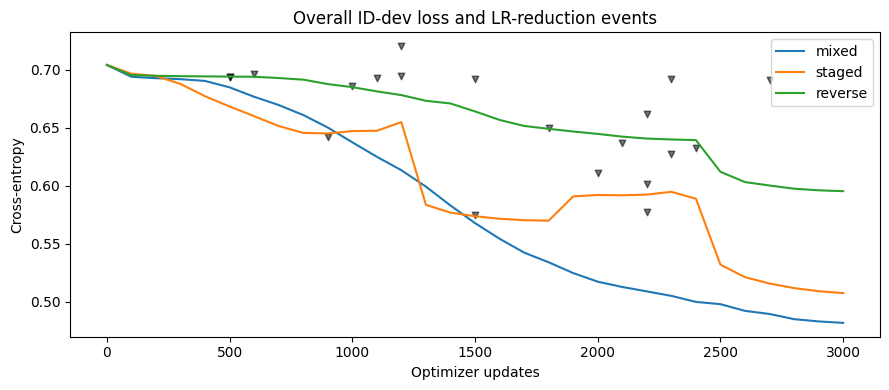

In [10]:
events = history.merge(lr_events[['seed', 'schedule', 'step']],
                       on=['seed', 'schedule', 'step'])[['seed', 'schedule', 'step', 'phase', 'lr', 'id_loss']]
display(events.sort_values(['schedule', 'seed', 'step']))
events.to_csv(OUTPUT_DIR / 'lr_reductions_by_phase.csv', index=False)
fig, ax = plt.subplots(figsize=(9, 4))
for schedule in SCHEDULES:
    h = history[history.schedule == schedule].groupby('step')['id_loss'].mean()
    ax.plot(h.index, h.values, label=schedule)
for _, e in events.iterrows():
    ax.scatter(e.step, e.id_loss, marker='v', color='black', s=22, alpha=.55)
ax.set(title='Overall ID-dev loss and LR-reduction events', xlabel='Optimizer updates',
       ylabel='Cross-entropy')
ax.legend()
plt.tight_layout()
save_figure(fig, 'loss_and_lr_reduction_events')
plt.show()

## Reading the evidence

This study compares complete training procedures, not pure order effects: equal example budgets **do not imply equal realized learning-rate trajectories**. The follow-up rehearsal experiment holds LR fixed across schedules. In both experiments, use the paired-seed outcomes and OOD results before proposing a curriculum advantage; avoid choosing the best seed or adjusting policy from test data.